# Supplementary Figure S1 — Hi-C contact frequency vs. genomic distance

HOMER-style log-log decay for three GM12878 samples: bulk NOMe-HiC, pseudobulk
NOMe-HiC, and ENCODE in-situ Hi-C. Full depth, log-binned 20/decade, zoomed to
10^5–10^8 bp.

Panel: `hic_loglog_contact_vs_distance.fullonly.smoothed.zoom.pdf`

Input: `<sample>_full.petag.FreqDistribution_1000.txt` — HOMER
`makeTagDirectory` writes these from a HiCsummary read-pair file. They are produced
by `sample_pipeline.sh` in the source folder (see `FILES.md`), which is not carried
here: it needs the ~115 GB ENCODE pairs download and the bulk/pseudobulk read-pair
files.


In [1]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

RESULTS = WORK + "/analysis/fig1/results/hic_qc_loglog"

# (base_name, label, color); each sample has a *_full and a 100M-subsample ("") run
SAMPLES = [
    ("bulk_nomehic",       "bulk NOMe-HiC",         "#1f77b4"),
    ("pseudobulk_nomehic", "pseudobulk NOMe-HiC",   "#ff7f0e"),
    ("insitu_hic",         "in-situ Hi-C (ENCODE)", "#2ca02c"),
]
os.path.isdir(RESULTS)

True

In [ ]:
def load(path):
    """Read a HOMER petag.FreqDistribution_1000.txt -> (distance_bp, fraction) for
    intrachromosomal bins (>0), renormalized to sum 1 so curves are comparable across depth."""
    dist, frac = [], []
    with open(path) as fh:
        for line in fh:
            parts = line.rstrip("\n").split("\t")
            key = parts[0].strip()
            if key.lower().startswith("inter"):      # skip header / interchromosomal
                continue
            try:
                d = float(key); f = float(parts[1])
            except (IndexError, ValueError):
                continue
            dist.append(d); frac.append(f)
    d = np.array(dist); f = np.array(frac)
    o = np.argsort(d); d, f = d[o], f[o]
    m = (d > 0) & (f > 0); d, f = d[m], f[m]     # drop <1kb local bin
    s = f.sum()
    if s > 0:
        f = f / s
    return d, f

def logbin(d, f, per_decade=20):
    """Geometric (log-spaced) re-binning: mean per-1kb fraction within each bin.
    Smooths the noisy long-range tail while keeping the same y-scale."""
    lo, hi = d.min(), d.max()
    nbins = max(4, int(np.ceil((np.log10(hi) - np.log10(lo)) * per_decade)))
    edges = np.logspace(np.log10(lo), np.log10(hi), nbins + 1)
    xs, ys = [], []
    for i in range(nbins):
        m = (d >= edges[i]) & (d < edges[i + 1] if i < nbins - 1 else d <= edges[i + 1])
        if not m.any():
            continue
        y = f[m].mean()
        if y > 0:
            xs.append(np.sqrt(edges[i] * edges[i + 1])); ys.append(y)
    return np.array(xs), np.array(ys)

def _exp_fmt(v, pos):
    """Tick label = exponent only: 10^X -> 'X'."""
    if v <= 0:
        return ""
    e = np.log10(v); er = round(e)
    return f"{int(er)}" if abs(e - er) < 1e-6 else ""

In [ ]:
def make_fig(smoothed=True, full_only=False, sub_only=False, zoom=False, save=False):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    yin = []
    if full_only:
        variants = [("_full", "-", 1.0, "full")]
    elif sub_only:
        variants = [("", "-", 1.0, "100M sub")]
    else:
        variants = [("_full", "-", 1.0, "full"), ("", "--", 0.7, "100M sub")]
    for base, label, color in SAMPLES:
        for suffix, ls, alpha, tag in variants:
            path = os.path.join(RESULTS, f"{base}{suffix}.petag.FreqDistribution_1000.txt")
            if not os.path.exists(path):
                print("[skip] missing", path); continue
            d, f = load(path)
            if smoothed:
                d, f = logbin(d, f)
            if zoom:
                mm = (d >= 1e5) & (d <= 1e8) & (f > 0)
                if mm.any():
                    yin.extend(f[mm].tolist())
            lbl = label if (full_only or sub_only) else f"{label} ({tag})"
            ax.plot(d, f, color=color, lw=1.8 if smoothed else 1.2, ls=ls, alpha=alpha, label=lbl)
    ax.set_xscale("log"); ax.set_yscale("log")
    if zoom:
        ax.set_xlim(1e5, 1e8)
        if yin:
            ax.set_ylim(min(yin) / 2.0, max(yin) * 2.0)
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_locator(LogLocator(base=10.0))
            axis.set_major_formatter(FuncFormatter(_exp_fmt))
            axis.set_minor_formatter(NullFormatter())
        ax.set_xlabel("log$_{10}$ genomic distance (bp)")
        ax.set_ylabel("log$_{10}$ contact frequency (fraction per 1 kb bin)")
    else:
        ax.set_xlabel("Genomic distance between paired reads (bp)")
        ax.set_ylabel("Contact frequency (mean fraction per 1 kb bin)")
    sub = "log-binned (20/decade)" if smoothed else "raw 1 kb bins"
    tail = "full depth" if full_only else ("100M subsample" if sub_only else "solid = full, dashed = 100M sub")
    ax.set_title(f"Hi-C contact frequency vs. distance (HOMER)\n{sub}  \u00b7  {tail}")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(True, which="both", ls=":", lw=0.4, alpha=0.5)
    fig.tight_layout()
    if save:
        stem = "hic_loglog_contact_vs_distance"
        stem += ".fullonly" if full_only else ""
        stem += ".subonly" if sub_only else ""
        stem += ".smoothed" if smoothed else ""
        stem += ".zoom" if zoom else ""
        fig.savefig(os.path.join(RESULTS, stem + ".png"), dpi=200)
        fig.savefig(os.path.join(RESULTS, stem + ".pdf"))
        print("saved", stem)
    return fig

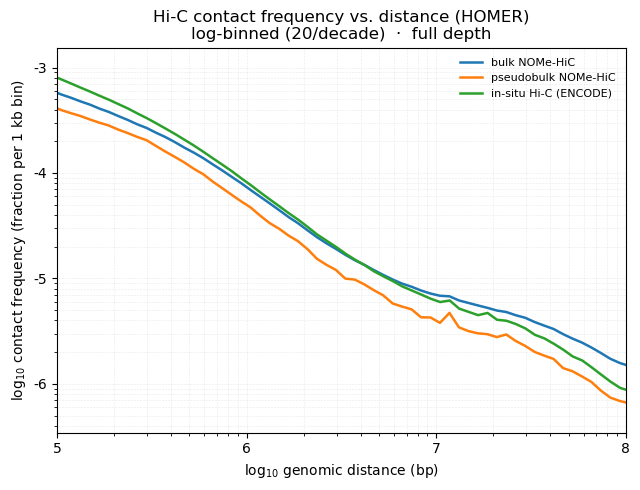

In [6]:
make_fig(smoothed=True, full_only=True, zoom=True);
